# 수험번호를 반드시 입력하세요!

**문제를 시작하기 전에, 바로 아래 셀의 `student_id`에 본인의 수험번호를 입력하고 실행하세요.**

예: `student_id = '001234'` — 앞자리 0도 포함하여 따옴표 안에 입력하세요.


In [1]:
# 본인의 수험번호를 따옴표 안에 입력하세요. 예: '001234'
student_id = '000000'   # [정답안] 예시 번호
if not student_id or not student_id.isascii() or not student_id.isdigit():  # 비어 있거나, 영숫자 외 문자가 있거나, 숫자가 아니면 오류
    raise ValueError('수험번호를 숫자로만 입력하세요. 앞자리 0도 그대로 적습니다.')  # 수험번호 형식 오류를 알리고 실행을 멈춤
print('수험번호:', student_id)  # 입력한 수험번호를 화면에 출력

수험번호: 000000


## 코드 작성 안내
- 답안 작성과 관련 있는 셀은 앞쪽에 `답안 작성 셀`로 시작하는 마크다운 셀이 있습니다.
- 수정이 불가한 셀에는 `# 수정 금지`로 표시가 되어있습니다. 해당 주석이 있는 셀의 코드는 절대 수정하지 마세요.
- 수정 가능한 셀은 `# 수정 가능`으로 표시가 되어있습니다. 다만 셀 안에서 함수명 등 변경하면 안되는 부분도 있으니, 그런 경우 해당 셀 혹은 문항의 안내를 참고하세요.

# 문제 1-1. (예측)

> **[예측 문제]** 공식 샘플의 형식·제약을 그대로 따르고 데이터와 함정만 바꾼 연습 문제입니다. 실제 시험 문제가 아닙니다.

> 나는 온라인 패션 쇼핑몰의 데이터 담당자다. 이번 시즌부터 **협력사 세 곳이 보내 준 상품 사진을 기존 학습 데이터에 합쳐** 상품 분류 모델을 다시 학습했다. \
> 그런데 합친 뒤로 오히려 **샌들·조리·힐, 셔츠·티셔츠, 운동화·캐주얼화** 쪽에서 오분류가 늘었다는 보고가 들어왔다.

>> “협력사 데이터가 들어오면서 학습 데이터 자체에 문제가 생긴 것 같습니다. 업로드 과정에서 파일이 깨지거나 같은 파일이 여러 번 올라온 흔적도 있어요.”

> 나는 학습 데이터를 점검하고, **학습에 쓸 항목을 골라내고(제외 가능)** 필요하면 보강하여 성능을 회복하려 한다.

### 문제 안내
서비스 팀에서 수정을 요청한 셀에는 표시가 되어 있습니다. 그 외 셀은 수정하지 마세요.

- 환경 제약으로 **TinyViT 5M을 Linear Probing으로 10 epoch** 학습한 모델만 사용합니다. 모델·Loss·학습률·batch 크기는 고정입니다.
- 제공된 train만 사용하세요. **train 항목을 학습에서 제외하는 것은 허용**됩니다.
- 클래스 번호와 원본 이미지 크기(높이 80 × 너비 60)를 유지하세요.

> ## [예측 문제 정답안]
> 라벨 충돌 사본·손상·반복 이미지를 해시와 통계로 찾아 제외 → 오버샘플링 + 증강으로 균형

참고 자료는 [오프라인 문서 목록](docs/index.html)에서 볼 수 있습니다. `docs` 폴더를 함께 보관하세요.


## 환경 설정 (실행 필수)
아래 셀들은 가상환경이 설정되어 있으며 커널이 해당 가상환경으로 잡혀있는지를 체크합니다.\
꼭 실행해서 확인 후에 진행하셔야 하며, 그렇지 않은 경우 폴더 루트의 README.md를 참조하여 다시 데이터셋을 참조하기 바랍니다.\
특히 VSCode, Pycharm 환경에서 Jupyter Notebook 커널을 꼭 확인하세요.


In [2]:
# [정답안] 환경 확인 - CPU/GPU 겸용 (문제 노트북은 GPU가 없으면 여기서 멈춥니다)
import sys  # 파이썬 인터프리터 정보(sys.prefix, sys.executable)를 쓰기 위한 모듈
from pathlib import Path  # 경로를 객체로 다루는 Path 클래스

print('Python:', sys.version.split()[0])  # 현재 파이썬 버전 출력 (예: 3.12.10)
print('현재 커널:', sys.executable)  # 지금 노트북을 실행 중인 python.exe 경로 출력 → .venv인지 확인
print('작업 폴더:', Path.cwd())  # 현재 작업 폴더 출력 (상대 경로 data/... 의 기준)
expected_env = Path.cwd() / '.venv'  # 작업 폴더 아래 .venv 폴더 경로를 기대값으로 만듦
if Path(sys.prefix).resolve() != expected_env.resolve():  # 실행 중인 파이썬의 환경 폴더가 기대한 .venv와 다르면
    raise RuntimeError(f"{expected_env / 'Scripts' / 'python.exe'}를 노트북 커널로 선택하세요.")  # 잘못된 커널 오류
import torch, torchvision, timm  # 세 라이브러리 한 번에 불러오기
print('PyTorch:', torch.__version__, '/ torchvision:', torchvision.__version__, '/ timm:', timm.__version__)  # 설치된 세 라이브러리 버전 출력
if torch.cuda.is_available():  # CUDA GPU를 쓸 수 있으면
    DEVICE, QUICK = 'cuda', False  # 장치는 GPU, QUICK(축소 실행) 모드는 끔
    print('GPU:', torch.cuda.get_device_name(0), '-> 원본 설정 그대로 실행합니다.')  # GPU 이름 출력
else:  # 그렇지 않으면 (아래 실행)
    DEVICE, QUICK = 'cpu', True  # 장치는 CPU, QUICK 모드 켬 → 뒤의 [정답안 전용] 셀이 데이터·epoch를 줄임
    print('GPU 없음 -> QUICK 모드: 학습 데이터와 epoch를 줄여 CPU에서 끝까지 실행합니다 (점수는 낮게 나옴).')  # CPU 실행 안내

Python: 3.12.10
현재 커널: C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution\.venv\Scripts\python.exe
작업 폴더: C:\Users\SSAFY\Desktop\AI_Lv3_final_predict


C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.11.0+cu128 / torchvision: 0.26.0+cu128 / timm: 1.0.31
GPU: NVIDIA GeForce RTX 5060 Ti -> 원본 설정 그대로 실행합니다.


In [3]:
# 수정 금지

from pathlib import Path  # 경로를 객체로 다루는 Path 클래스
import json  # JSON 파일(classes.json) 읽기용
import random  # 파이썬 기본 난수 (시드 고정용)
import time  # 학습 시간 측정용

import numpy as np  # NumPy: 이미지 배열(N, H, W, 3) 처리
import matplotlib.pyplot as plt  # 그래프 그리기
import torch  # PyTorch: 텐서 연산·자동 미분·신경망
from torch import nn  # nn: 신경망 층(Linear, Conv2d 등)과 Loss 클래스
from torch.utils.data import Dataset, DataLoader  # Dataset(데이터 한 개 꺼내기 규칙), DataLoader(배치로 묶기)
from torchvision import transforms as T  # 이미지 변환 모음을 T라는 이름으로 사용 (V1 API)
import timm  # timm: 사전학습 이미지 모델 라이브러리 (P1_1에서 모델 생성에 사용)
from sklearn.metrics import f1_score  # F1 점수 계산 함수

random.seed(42)  # 파이썬 random 시드 고정 → 실행마다 같은 결과
np.random.seed(42)  # NumPy 난수 시드 고정
torch.manual_seed(42)  # PyTorch 난수 시드 고정 (가중치 초기화, shuffle 순서)
device = 'cuda' if torch.cuda.is_available() else 'cpu'  # GPU가 있으면 'cuda', 없으면 'cpu'를 장치로 사용
print('사용 장치:', torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU')  # 사용 장치 이름 출력


사용 장치: NVIDIA GeForce RTX 5060 Ti


### 데이터 준비 (실행 필수)

환경과 데이터는 이미 준비되어 있습니다. 아래 셀들을 실행하여 데이터를 메모리에 준비시킵니다.

#### 참고 사항
- 노트북 커널/인터프리터는 이 폴더의 `.venv\Scripts\python.exe`를 선택합니다.
- 데이터는 같은 폴더의 `data/`에서 읽습니다. 이미지는 RGB, 가로 60 × 세로 80이며 리사이즈하지 않습니다.
- 이 노트북에서는 데이터를 다운로드하거나 다시 분할하지 않습니다. **validation 데이터는 변경하지 마세요.**
- P1_1, P1_2, P2_1, P2_2는 노트북과 같은 폴더의 `tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors` 파일을 함께 사용합니다. 사전학습 가중치를 다운로드할 필요가 없습니다.


In [4]:
# 수정 금지

data_path = Path('data/f1_1_noisy/prepared.npz')  # F1_1 데이터 파일
if not data_path.is_file() or not data_path.with_name('classes.json').is_file():  # npz 파일이나 같은 폴더의 classes.json이 없으면
    raise FileNotFoundError('데이터가 없습니다. 먼저 setup.cmd를 실행하고, 작업 폴더를 이 노트북이 있는 폴더로 맞추세요.')  # 데이터 준비가 안 됐다는 오류

In [5]:
# 수정 금지

with data_path.with_name('classes.json').open(encoding='utf-8') as file:  # classes.json을 UTF-8로 열기 (with: 끝나면 자동으로 닫힘)
    class_names = json.load(file)  # 클래스 이름 목록 읽기 (목록 순서 = 클래스 번호)
num_classes = len(class_names)  # 클래스 개수

with np.load(data_path, allow_pickle=False) as data:  # npz 열기 (allow_pickle=False: 안전하게 배열만 읽음)
    train_images = data['train_images']  # 학습 이미지 배열 (N, 80, 60, 3) uint8
    train_labels = data['train_labels']  # 학습 정답 번호 배열 (N,)
    val_images = data['val_images']  # 검증 이미지 배열
    val_labels = data['val_labels']  # 검증 정답 번호 배열

print('학습:', len(train_labels), '검증:', len(val_labels))  # 학습·검증 데이터 개수 출력
print('이미지 크기:', train_images.shape[1:])  # 이미지 한 장의 모양 (높이, 너비, 채널) 출력


학습: 6996 검증: 1000
이미지 크기: (80, 60, 3)


### 데이터셋과 수행할 Task

Fashion Products 데이터에서 상품 이미지 10종을 분류합니다. \
이미지 한 장을 입력받아 상품 종류 하나를 예측하는 문제입니다. 

먼저 학습 데이터의 분석을 진행합니다. \
Task 에서는 데이터 전처리를 설계한 뒤, 고정된 Linear Probing 모델(전체 모델에서 마지막 Linear 레이어만 학습하고, 나머지는 초기 값으로 고정하는 학습법)의 학습 결과를 확인합니다.

데이터는 이미지 파일을 하나씩 여는 방식이 아니라, NumPy 배열을 압축한 `prepared.npz`와 클래스 이름 목록인 `classes.json`에 저장되어 있습니다.


### 힌트
| 항목 | 자료형과 모양 | 의미 |
| --- | --- | --- |
| `train_images` | `np.ndarray`, `uint8`, `(N, 80, 60, 3)` | 학습 RGB 이미지, 픽셀 범위 0~255 |
| `train_labels` | `np.ndarray`, `int64`, `(N,)` | 같은 위치의 이미지에 대응하는 클래스 번호 |
| `classes.json` | JSON 문자열 목록 → `list[str]` | 목록의 인덱스가 클래스 번호 |

예를 들어 `train_images[i]`의 정답은 `train_labels[i]`이고, 클래스 이름은 `class_names[train_labels[i]]`입니다. 검증 데이터도 `val_images/val_labels`로 같은 형식으로 저장됩니다. 

**Task 에서는 train만 사용합니다.**

0번 이미지: <class 'numpy.ndarray'> (80, 60, 3) uint8
0번 라벨: 4 클래스 이름: Watches
{'Tshirts': 788, 'Shirts': 521, 'Casual Shoes': 791, 'Sports Shoes': 517, 'Watches': 744, 'Handbags': 738, 'Heels': 525, 'Sandals': 1073, 'Flip Flops': 788, 'Kurtas': 511}


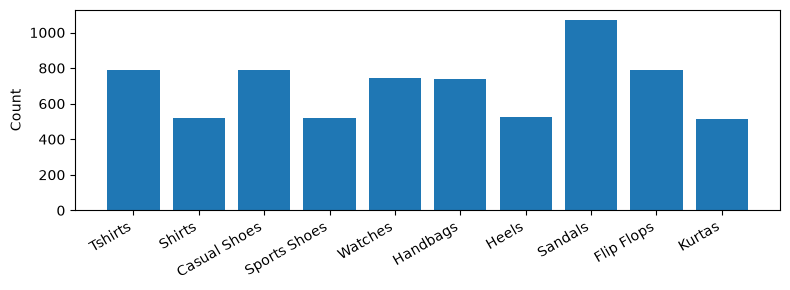

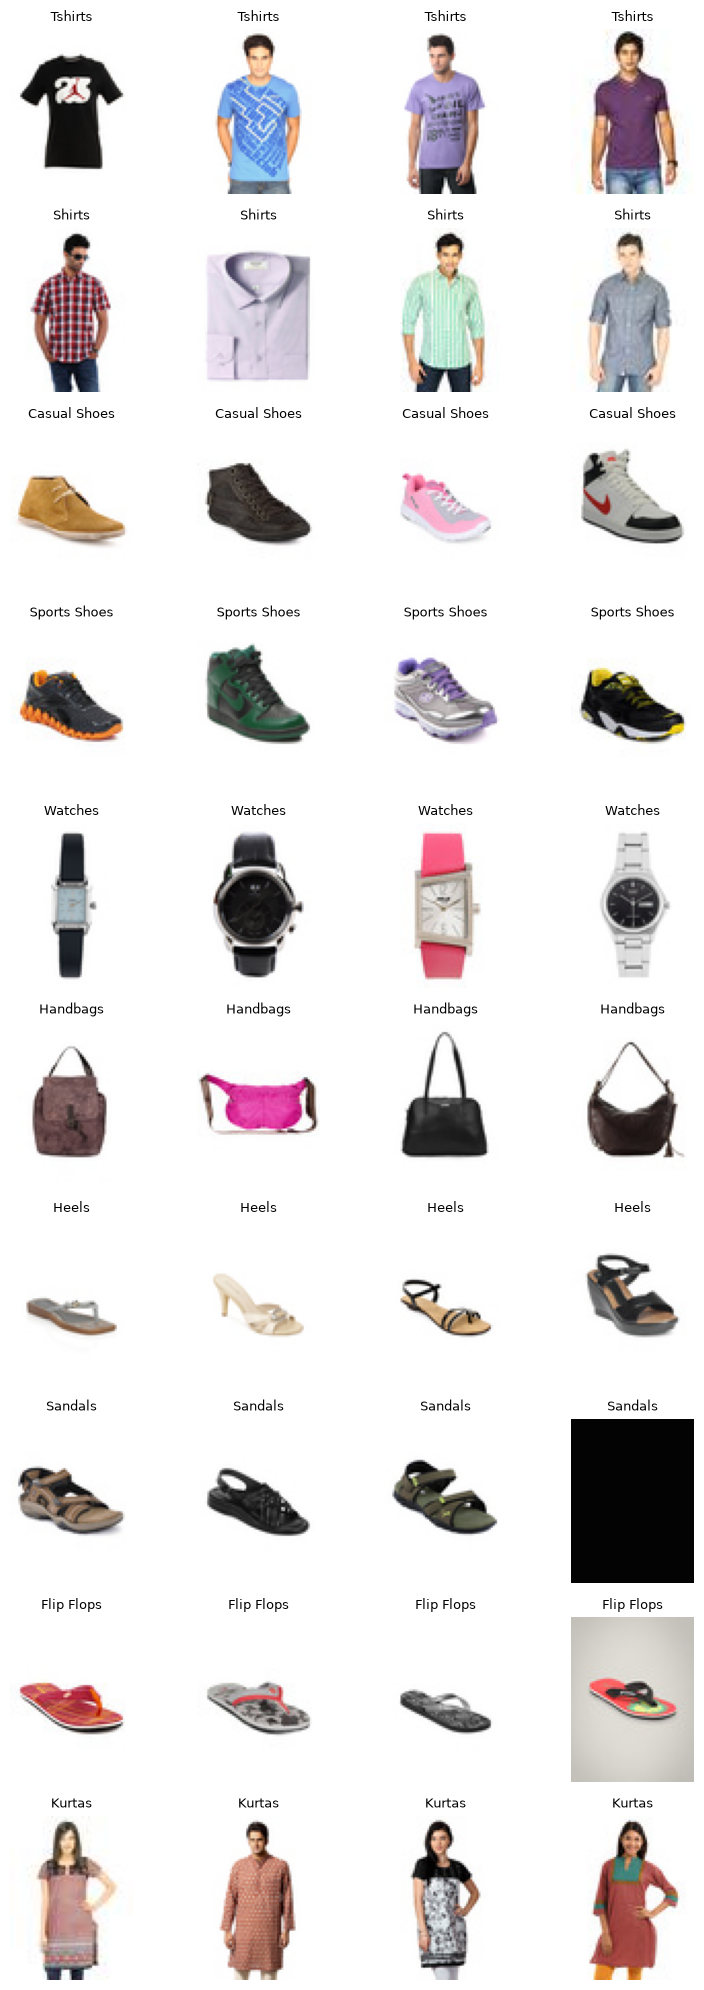

In [6]:
# 수정 금지
# 데이터 접근 예시입니다.

with np.load(data_path, allow_pickle=False) as data:  # npz 열기 (allow_pickle=False: 안전하게 배열만 읽음)
    image_0 = data['train_images'][0]  # 0번 학습 이미지 하나만 꺼냄
    label_0 = data['train_labels'][0]  # 0번 이미지의 정답 번호

print('0번 이미지:', type(image_0), image_0.shape, image_0.dtype)  # 자료형, 모양, 픽셀 자료형 확인
print('0번 라벨:', label_0, '클래스 이름:', class_names[int(label_0)])  # 정답 번호와 클래스 이름 출력


def count_class_images(dataset_path):  # 클래스별 학습 이미지 수를 세는 함수 정의
    """prepared.npz와 classes.json을 읽어 학습 이미지 수를 집계합니다."""  # 함수 설명(docstring)
    dataset_path = Path(dataset_path)  # 문자열 경로를 Path 객체로 바꿈
    with dataset_path.with_name('classes.json').open(encoding='utf-8') as file:  # 같은 폴더의 classes.json 열기
        names = json.load(file)  # 클래스 이름 목록
    with np.load(dataset_path, allow_pickle=False) as data:  # npz 열기
        labels = data['train_labels']  # 학습 라벨만 읽음

    counts = {name: 0 for name in names}  # 클래스 이름마다 0으로 시작하는 개수 사전
    for label in labels:  # 라벨을 하나씩 돌면서
        counts[names[int(label)]] += 1  # 해당 클래스 이름의 개수를 1 증가
    return counts  # {클래스 이름: 개수} 반환


class_counts = count_class_images(data_path)  # 클래스별 개수 계산
print(class_counts)  # 개수 출력 → 불균형 여부를 숫자로 확인

plt.figure(figsize=(8, 3))  # 가로 8, 세로 3인치 그림 시작
plt.bar(class_names, [class_counts[name] for name in class_names])  # 클래스별 개수 막대그래프
plt.xticks(rotation=30, ha='right')  # x축 글자를 30도 기울여 겹치지 않게
plt.ylabel('Count')  # y축 이름
plt.tight_layout()  # 여백 자동 정리
plt.show()  # 그림 표시

fig, axes = plt.subplots(num_classes, 4, figsize=(8, num_classes * 2), squeeze=False)  # 클래스 수 × 4칸 격자 (squeeze=False: 항상 2차원 배열)
for label in range(num_classes):  # 클래스마다
    for axis in axes[label]:  # 그 클래스 줄의 칸들을
        axis.axis('off')  # 축 눈금·테두리 숨김
    examples = np.flatnonzero(train_labels == label)[:4]  # 해당 클래스 이미지의 위치(인덱스) 중 앞 4개
    for column, index in enumerate(examples):  # 칸 번호와 이미지 위치를 함께 돌며
        axes[label, column].imshow(train_images[index])  # 그 칸에 이미지 표시
        axes[label, column].set_title(class_names[label], fontsize=9)  # 칸 제목에 클래스 이름
plt.tight_layout()  # 여백 자동 정리
plt.show()  # 그림 표시


# **답안 작성 셀 - 데이터 전처리**

> 데이터와 관련된 성능 저하에 관한 영향에 대해서 조사했더니, 다음과 같은 경우들이 있는 것을 확인하였다. 

> - **데이터 부족**: 학습에 필요한 데이터가 부족하거나 특정 상황의 사례가 충분하지 않음.
> - **클래스 불균형**: 일부 클래스에 데이터가 편중되어 데이터가 적은 클래스의 특성을 충분히 학습하지 못함.
> - **라벨 오류**: 잘못된 정답이 부여되거나 동일한 기준으로 라벨링되지 않음.
> - **낮은 데이터 품질**: 이미지 손상, 흐림, 가림, 낮은 해상도 등으로 분류에 필요한 정보를 확인하기 어려움.
> - **데이터 다양성 부족**: 촬영 각도, 조명, 배경, 대상의 형태 등이 제한적이어서 새로운 조건에 대응하기 어려움.
> - **데이터 분포 차이**: 학습 데이터와 평가·실제 서비스 데이터의 특성이 달라 학습한 패턴이 잘 적용되지 않음.
> - **부적절한 전처리**: 크기 조정, 정규화, 색상 처리 등에서 필요한 정보가 손실되거나 모델이 기대하는 입력 형식과 달라짐.
> - **부적절한 데이터 증강**: 증강이 실제 환경을 반영하지 못하거나 대상을 과도하게 변형하여 정답의 의미를 훼손함.
> - **중복·유사 데이터 편중**: 데이터 수에 비해 새로운 정보가 적어 특정 사례를 반복적으로 학습함.
> - **데이터 분할 문제**: 학습·검증 데이터가 전체 특성을 고르게 반영하지 못해 성능이 낮거나 불안정하게 측정됨.
> - **데이터 누수**: 평가 데이터나 정답을 유추할 수 있는 정보가 학습에 포함되어 평가 성능과 실제 성능 사이에 차이가 발생함.
> - **클래스 정의의 모호함**: 클래스 간 구분 기준이 불명확하거나 서로 겹쳐 일관된 학습과 평가가 어려움.
> - **입력 정보의 한계**: 정답을 구분하는 데 필요한 특징이 입력 데이터에 없거나 충분히 드러나지 않음.
> - **우연한 단서에 대한 편향**: 대상의 본질적인 특징보다 배경, 워터마크, 촬영 방식 등 정답과 우연히 연결된 단서를 학습함.

> 위 목록 중 **두 가지 이상**이 섞여 있는 것 같다. \
> 이제 감을 잡았다. 해결책을 구현하기만 하면 될 것 같다. \
> 문제가 있는 항목은 학습에서 빼고, 그 때문에 부족해진 클래스는 증강으로 보강하자!


### 문제 목표
위에서 확인한 데이터 분석을 바탕으로, 현재 학습 데이터셋의 문제를 파악하고, 그 문제 해결을 위한 적절한 전처리 및 변환을 설계하세요.  \
아래 한 셀에 있는 **`train_transform`과 `processing_training_data()`**에서 필요한 부분을 적절히 수정하세요. \
아래 `processing_training_data` 함수 예시를 보고, 데이터 변환(증강)이 적용하는 전략을 구현하는 함수입니다. 이미지 변환은 해당 항목의 flag가 True일 때만 적용되고, False인 데이터에는 적용되지 않습니다.

`processing_training_data`는 학습에 사용할 원본 인덱스와 각 항목에 적용할 transform을 정하는 flag를 반환합니다. \
아래 `FashionDataset`에서 flag가 어떻게 사용되는지 확인하세요. 이 클래스는 제공 코드이며 수정하면 안 됩니다.

- 제공된 train 안에서만 데이터를 구성하고, 클래스 번호와 정답의 대응을 유지하세요.
- transform의 출력은 정규화된 `torch.float32` 텐서이며 크기는 `(3, 80, 60)`으로 유지하세요.
- 아래 제공된 정규화 값과 `eval_transform`, 검증 데이터, 모델·학습·평가 코드는 변경하지 마세요.



### 공식 문서

- [torchvision Transform 종류와 사용법](docs/pages/docs.pytorch.org/vision_0.26_transforms--d97759c5de81.html)
- [Transform 적용 결과를 그림으로 비교하는 예제](docs/pages/docs.pytorch.org/vision_0.26_auto_examples_transforms_plot_transforms_illustrations--0d046f058aa3.html)

이 노트북은 `torchvision.transforms`를 사용합니다. 문서의 V1 API Reference를 참고하세요. 시각화 예제에는 `transforms.v2` 코드가 있으므로 import와 사용법을 구분해 참고하세요.


### 추가 안내 (예측 문제)
- `processing_training_data(labels)`는 **라벨만** 인자로 받습니다. 이미지 내용을 확인하려면 이 함수 안에서 전역 변수 `train_images`를 읽어도 됩니다(읽기만, 수정 금지).
- 반환하는 `indices`에서 원본 번호를 **빼면 그 항목은 학습에서 제외**됩니다.
- 이미지 비교에는 NumPy 연산, `hashlib` 등 표준 라이브러리를 써도 됩니다.
- 아래 셀에 무엇을 발견했고 왜 그렇게 처리했는지 **주석으로 남기세요** (채점 요소).

In [7]:
# 수정 금지
mean = (0.485, 0.456, 0.406)  # ImageNet 채널별 평균 (사전학습 때 쓴 값)
std = (0.229, 0.224, 0.225)  # ImageNet 채널별 표준편차
eval_transform = T.Compose([  # 평가용 변환: 증강 없이 텐서 변환 + 정규화만
    T.ToTensor(),  # numpy(H,W,C) 0~255 → 텐서(C,H,W) 0~1 실수
    T.Normalize(mean, std),  # (값 - mean) / std 로 정규화
])


In [8]:
# 수정 가능
# train_transform과 processing_training_data는 자유롭게 수정해도 됩니다.
# 다만, train_transform과 processing_training_data의 이름과 매개변수는 변경하지 마세요.
import hashlib  # md5 해시 (이미지 내용 비교용)

# [정답안] 보강용 약한 증강 (상품 정체성 유지, 흰 배경 채움, 80x60 유지)
train_transform = T.Compose([  # 학습용 변환을 차례로 묶음
    T.ToPILImage(),  # numpy 배열 → PIL 이미지 (Random* 변환은 PIL/텐서만 받음)
    T.RandomHorizontalFlip(p=0.5),  # 50% 확률로 좌우 반전 (상품 종류는 그대로)
    T.RandomAffine(degrees=8, translate=(0.06, 0.06), scale=(0.92, 1.08), fill=255),  # 회전 ±8°, 이동 ±6%, 크기 0.92~1.08배, 빈 곳은 흰색(255)으로 채움
    T.ColorJitter(brightness=0.2, contrast=0.2),  # 밝기·대비를 ±20% 범위에서 무작위로 바꿈
    T.ToTensor(),  # numpy(H,W,C) 0~255 → 텐서(C,H,W) 0~1 실수
    T.Normalize(mean, std),  # (값 - mean) / std 로 정규화
])


def image_is_broken(image):  # 손상 이미지 판별 함수
    """손상 이미지: (1) 거의 단색(빈 흰/검은 화면)  (2) 이웃 픽셀 차이가 비정상적으로 큰 잡음."""  # 함수 설명(docstring)
    pixels = image.astype(np.int16)  # 음수 차이를 계산하려고 int16으로 변환 (uint8은 넘침)
    if pixels.std() < 3:  # 표준편차가 거의 0 = 단색 화면이면
        return True  # 손상
    roughness = np.abs(np.diff(pixels, axis=1)).mean()   # 실제 사진은 이웃 픽셀이 비슷 (보통 < 15)
    return roughness > 40  # 이웃 픽셀 차이 평균이 매우 크면 잡음 → 손상


def processing_training_data(labels):  # 학습에 쓸 원본 번호와 증강 여부를 정하는 함수 (이름·인자 고정)
    """[정답안]
    발견한 문제
      1) 라벨 오류: 내용이 '완전히 같은' 이미지가 서로 다른 라벨로 들어 있음
         (협력사 업로드 오류: Sandals<->Flip Flops, Shirts->Tshirts, Sports->Casual Shoes, Heels->Sandals)
      2) 낮은 품질: 빈 흰 화면, 검은 화면, 잡음 이미지 (라벨이 무작위)
      3) 중복 편중: 같은 사진이 15번씩 반복 (Watches, Handbags)
    처리
      - 모든 이미지를 md5로 묶어, 한 묶음에 라벨이 2개 이상이면 '어느 쪽이 맞는지 알 수 없으므로' 묶음 전체 제외
      - 라벨이 하나인 묶음은 1장만 남김 (반복 제거)
      - 손상 이미지는 제외
      - 정리 후 클래스 수가 달라지므로, 가장 많은 클래스 수까지 오버샘플링하고 반복분에만 증강(flag=True)
    """
    labels = np.asarray(labels)  # 리스트가 와도 numpy 배열로 바꿈
    groups = {}  # {해시: [번호들]}
    for index in range(len(labels)):  # 모든 이미지에 대해
        key = hashlib.md5(train_images[index].tobytes()).hexdigest()  # 픽셀 바이트의 md5 = 내용이 같으면 같은 값
        groups.setdefault(key, []).append(index)  # 같은 해시끼리 번호를 모음

    keep = []  # 남길 번호
    removed = {'conflict': 0, 'duplicate': 0, 'broken': 0}  # 제외 사유별 개수
    for members in groups.values():  # 같은 내용 묶음마다
        if len(set(labels[members].tolist())) > 1:  # 묶음 안 라벨이 2종 이상이면 (라벨 충돌)
            removed['conflict'] += len(members)  # 묶음 전체 제외 (어느 쪽이 맞는지 모름)
            continue  # 건너뜀
        first = members[0]  # 대표로 첫 번째만
        removed['duplicate'] += len(members) - 1  # 나머지 반복분은 제외
        if image_is_broken(train_images[first]):  # 대표가 손상 이미지면
            removed['broken'] += 1  # 제외
            continue  # 건너뜀
        keep.append(first)  # 남김
    keep = np.array(sorted(keep))  # 정렬된 배열로
    print('제외한 항목:', removed, '/ 남은 항목:', len(keep))  # 제외 내역 출력 (채점 근거)

    rng = np.random.default_rng(42)  # 재현 가능한 난수 생성기 (시드 42)
    counts = np.bincount(labels[keep], minlength=num_classes)  # 정리 후 클래스별 개수
    print('정리 후 클래스별 수:', dict(zip(class_names, counts.tolist())))  # 출력
    target = counts.max()  # 가장 많은 클래스의 개수 = 맞출 목표 개수
    indices, augment_flags = [], []  # 결과를 모을 빈 리스트 두 개
    for label in range(num_classes):  # 클래스마다
        members = keep[labels[keep] == label]  # 남긴 것 중 이 클래스 번호들
        indices.append(members)  # 원본 이미지는 모두 한 번씩 사용
        augment_flags.append(np.zeros(len(members), dtype=bool))  # 원본은 증강하지 않음 (False)
        if 0 < len(members) < target:  # 있으면서 목표보다 적으면
            indices.append(rng.choice(members, size=target - len(members), replace=True))  # 부족분을 중복 허용으로 뽑음
            augment_flags.append(np.ones(target - len(members), dtype=bool))  # 반복분은 증강
    return np.concatenate(indices).astype(int), np.concatenate(augment_flags).astype(bool)  # 이어 붙여 반환

### [정답안 해설]
| 점검 | 방법 | 발견 |
|---|---|---|
| 같은 내용, 다른 라벨 | `md5(image.tobytes())`로 묶고 라벨 종류 수 확인 | 협력사 사본 약 1,370장이 엉뚱한 라벨 |
| 손상 이미지 | 표준편차(단색) + 이웃 픽셀 차이(잡음) | 흰/검은/잡음 180장 |
| 반복 편중 | 같은 묶음 크기 | 같은 사진 15회 반복 450장 |

- **라벨이 엇갈린 묶음은 통째로 제외**: 원본과 사본 중 어느 쪽이 맞는지 이 함수 안에서는 알 수 없습니다(다수결은 사본이 2개인 경우 틀린 쪽을 고름).
- 정리 후 일부 클래스가 줄어드므로 **오버샘플링 + 반복분 증강**으로 균형을 맞춥니다(1-1 샘플과 같은 기법).
- 시험에서는 `print`로 발견 개수를 남기고, 무엇을 왜 뺐는지 주석으로 쓰는 것이 채점 요소입니다.

In [9]:
# 수정 금지
# Dataset은 제공 코드입니다. flag가 사용되는 위치를 확인하세요.

class FashionDataset(Dataset):  # 이미지·라벨·증강 여부로 샘플을 꺼내는 Dataset
    def __init__(self, images, labels, augment_flags=None):  # 생성자: 배열과 flag를 저장
        self.images = images  # 이미지 배열 저장
        self.labels = labels  # 라벨 배열 저장
        self.augment_flags = augment_flags  # 항목별 증강 여부 저장 (None이면 증강 없음)

    def __len__(self):  # 데이터 개수를 알려주는 함수 (DataLoader가 사용)
        return len(self.labels)  # 라벨 개수 = 데이터 개수

    def __getitem__(self, index):  # index번째 샘플을 꺼내는 함수
        image = self.images[index]  # numpy 이미지 하나
        if self.augment_flags is not None and self.augment_flags[index]:  # flag가 True인 항목이면
            image = train_transform(image)  # 학습용 변환(증강 포함) 적용
        else:  # 그렇지 않으면 (아래 실행)
            image = eval_transform(image)  # 아니면 평가용 변환(정규화만) 적용
        return image, int(self.labels[index])  # (이미지 텐서, 정수 라벨) 반환

In [10]:
# 수정 금지
# 아래 검사를 통과하면, 이어지는 학습·평가 셀을 실행해 결과를 확인하세요.

train_indices, augment_flags = processing_training_data(train_labels)  # 작성한 함수로 학습 목록 생성
train_indices = np.asarray(train_indices)  # numpy 배열로 변환
augment_flags = np.asarray(augment_flags)  # numpy 배열로 변환
assert train_indices.ndim == 1, '인덱스는 1차원 배열이어야 합니다.'  # 1차원인지 검사
assert augment_flags.ndim == 1, '증강 여부는 1차원 배열이어야 합니다.'  # 1차원인지 검사
assert len(train_indices) > 0, '학습 이미지를 하나 이상 선택하세요.'  # 비어 있지 않은지 검사
assert len(train_indices) == len(augment_flags), '인덱스와 증강 여부의 길이를 맞추세요.'  # 두 배열 길이가 같은지 검사
assert np.issubdtype(train_indices.dtype, np.integer), '인덱스는 정수여야 합니다.'  # 인덱스가 정수형인지 검사
assert augment_flags.dtype == bool, '증강 여부는 True 또는 False여야 합니다.'  # flag가 bool형인지 검사
assert train_indices.min() >= 0, '음수 인덱스는 사용할 수 없습니다.'  # 음수 인덱스가 없는지 검사
assert train_indices.max() < len(train_labels), '원본 train 범위를 벗어난 인덱스입니다.'  # 원본 범위를 넘지 않는지 검사

print('선택한 학습 항목:', len(train_indices), '증강할 항목:', int(augment_flags.sum()))  # 선택한 항목 수와 증강할 항목 수 출력


제외한 항목: {'conflict': 2389, 'duplicate': 455, 'broken': 60} / 남은 항목: 4092
정리 후 클래스별 수: {'Tshirts': 497, 'Shirts': 315, 'Casual Shoes': 500, 'Sports Shoes': 320, 'Watches': 500, 'Handbags': 500, 'Heels': 320, 'Sandals': 320, 'Flip Flops': 320, 'Kurtas': 500}
선택한 학습 항목: 5000 증강할 항목: 908


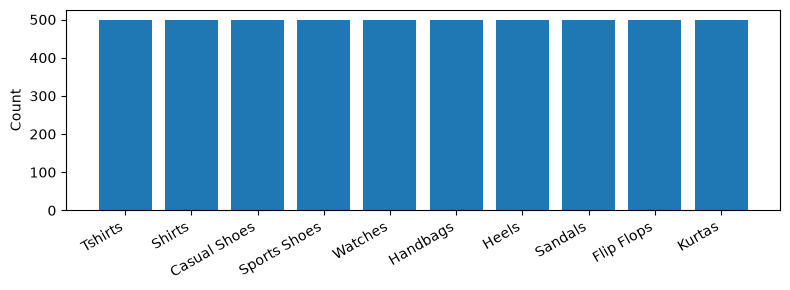

In [11]:
# 수정 금지
# 전처리 후 분포를 확인하는 제공 helper입니다.

def plot_class_counts(labels):  # 라벨 분포 히스토그램을 그리는 함수
    plt.figure(figsize=(8, 3))  # 가로 8, 세로 3인치 그림 시작
    plt.hist(labels, bins=np.arange(num_classes + 1) - 0.5, rwidth=0.8)  # 정수 라벨이 막대 가운데 오도록 경계를 -0.5씩 이동
    plt.xticks(range(num_classes), class_names, rotation=30, ha='right')  # x축에 클래스 이름 표시
    plt.ylabel('Count')  # y축 이름
    plt.tight_layout()  # 여백 자동 정리
    plt.show()  # 그림 표시


plot_class_counts(train_labels[train_indices])  # 구성한 학습 목록의 클래스 분포 확인 (균형이 맞았는지)


## 고정 Linear Probing

여기 이후 코드는 수정하지 않습니다.

TinyViT 모델을 Linear Probing 방식으로 학습하며, 하이퍼파라미터는 고정된 채로 진행합니다.\
macro-F1을 이용해 최종 성능을 확인합니다.\
최하단 셀의 `[Final] Validation macro-F1`에 출력되는 Validation macro-F1 score을 기준으로 성능 관련 점수가 부과될 예정입니다. 

기준은 아래와 같습니다. 
- High-level: 0.74 초과
- Mid-level: 0.68 초과 0.74 이하
- Low-level: 0.68 이하

In [12]:
# 수정 금지

batch_size = 64  # batch 크기: 한 번에 학습할 이미지 수
learning_rate = 0.0003  # 학습률
epochs = 10  # 전체 데이터를 몇 번 반복 학습할지 (고정)
output_dir = Path('outputs')  # 결과 저장 폴더
output_dir.mkdir(exist_ok=True)  # 폴더가 없으면 만듦 (있으면 그대로)
checkpoint = output_dir / f'F1_1_{student_id}.pt'  # 체크포인트

> **[정답안 전용 셀]** 시험 노트북에는 없는 셀입니다. GPU가 있으면 아무 일도 하지 않습니다.

In [13]:
if QUICK:  # CPU(QUICK) 모드일 때만
    epochs = 3  # epoch를 3으로 줄임
    print('QUICK 모드 epoch:', epochs)  # 줄인 epoch 출력

In [14]:
# 수정 금지

from safetensors.torch import load_file  # safetensors 형식 가중치 파일을 읽는 함수
from torch.nn import functional as F  # F: 함수형 API (interpolate, log_softmax, pad 등)


def load_pretrained_weights(model):  # 로컬 사전학습 가중치를 모델에 넣는 함수
    """제공된 로컬 가중치를 읽고 상대 위치 bias만 입력 크기에 맞게 보간합니다."""  # 함수 설명(docstring)
    path = Path('tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors')  # 노트북 옆에 있어야 할 가중치 파일
    if not path.is_file():  # 파일이 없으면
        raise FileNotFoundError(  # 오류 발생
            f'사전학습 가중치 파일을 찾을 수 없습니다: {path.resolve()}\n'  # 찾은 절대 경로를 오류 문구에 넣음
            '제공된 가중치 파일을 노트북과 같은 폴더에 두고, 작업 폴더를 해당 폴더로 맞추세요.'  # 오류 안내 두 번째 줄
        )
    weights = load_file(str(path))  # 가중치를 {이름: 텐서} 사전으로 읽음
    target = model.state_dict()  # 현재 모델의 {이름: 텐서} (모양 비교용)
    for name, value in weights.items():  # 가중치를 하나씩 돌며
        if name.endswith('attention_biases') and value.shape != target[name].shape:  # attention 상대 위치 bias인데 모양이 다르면 (window 크기를 줄였기 때문)
            num_heads, length = value.shape  # (head 수, window²) 모양 분해
            old_window = int(length ** 0.5)  # 원래 window 한 변 길이 (예: 49 → 7)
            new_window = int(target[name].shape[1] ** 0.5)  # 새 window 한 변 길이 (예: 9 → 3)
            weights[name] = F.interpolate(  # bias를 2차원 격자로 보고 크기를 줄임
                value.float().reshape(1, num_heads, old_window, old_window),  # (1, head, 원래 window, 원래 window) 이미지처럼 바꿈
                size=(new_window, new_window),  # 목표 크기
                mode='bicubic', antialias=True,  # bicubic 보간 + antialias (부드럽게 축소)
            ).reshape(num_heads, new_window * new_window)  # 다시 (head, 새 window²) 모양으로
    model.load_state_dict(weights, strict=True)  # strict=True: 모든 이름·모양이 정확히 맞아야 로딩 (빠진 것 있으면 오류)


class LinearProbe(nn.Module):  # Linear Probing 모델: 마지막 분류층만 학습
    def __init__(self):  # 생성자
        super().__init__()  # nn.Module 초기화 (필수)
        self.backbone = timm.create_model(  # timm으로 TinyViT 5M 구조 생성
            'tiny_vit_5m_224.dist_in22k_ft_in1k',  # 모델 이름
            pretrained=False, num_classes=1000, window_sizes=(3, 3, 5, 3),  # 가중치는 직접 넣고(pretrained=False), 작은 입력에 맞게 window 크기를 줄임
        )
        load_pretrained_weights(self.backbone)  # 로컬 가중치 로딩
        self.backbone.reset_classifier(num_classes)  # 분류층을 우리 클래스 수로 교체
        self.backbone.requires_grad_(False)  # 모든 파라미터 고정 (gradient 계산 안 함)
        self.backbone.head.fc.requires_grad_(True)  # 마지막 분류층(fc)만 다시 학습 가능하게

    def forward(self, x):  # 순전파 정의
        self.backbone.eval()  # 백본은 항상 평가 모드 (BatchNorm 통계 고정)
        with torch.no_grad():  # gradient 기록 없이 계산 (메모리·속도 절약)
            features = self.backbone.forward_features(x)  # 특징 맵 추출
            features = self.backbone.forward_head(features, pre_logits=True)  # 풀링·정규화된 특징 벡터 (분류 직전)
        return self.backbone.head.fc(features)  # 분류층만 gradient 계산 → 클래스 점수(logits)


In [15]:
# 수정 금지

def train_one_epoch(model, loader, optimizer, loss_fn):  # 한 epoch 학습 함수
    model.train()  # 학습 모드 (Dropout·BN이 학습 동작)
    total_loss = 0  # Loss 누적값
    sample_count = 0  # 샘플 수 누적값
    for images, labels in loader:  # DataLoader에서 배치를 하나씩 꺼냄
        images = images.to(device)  # 이미지를 GPU/CPU 장치로 이동
        labels = labels.to(device)  # 라벨도 같은 장치로
        logits = model(images)  # 순전파 → logits (B, 클래스 수)
        loss = loss_fn(logits, labels)  # Loss 계산
        loss.backward()  # 역전파: 각 파라미터의 gradient 계산
        optimizer.step()  # gradient로 파라미터 갱신
        optimizer.zero_grad()  # gradient를 0으로 초기화 (다음 배치에 누적되지 않게)
        total_loss += loss.item() * len(labels)  # 배치 평균 Loss × 배치 크기 = 배치 합계를 누적
        sample_count += len(labels)  # 처리한 샘플 수 누적
    return total_loss / sample_count  # 샘플 평균 Loss 반환


def evaluate(model, loader, loss_fn):  # 검증 함수
    model.eval()  # 평가 모드 (Dropout 끔, BN은 저장된 통계 사용)
    total_loss = 0  # Loss 누적값
    predictions, targets = [], []  # 예측과 정답을 모을 리스트
    with torch.no_grad():  # gradient 기록 없이 계산 (메모리·속도 절약)
        for images, labels in loader:  # DataLoader에서 배치를 하나씩 꺼냄
            images = images.to(device)  # 이미지를 GPU/CPU 장치로 이동
            labels = labels.to(device)  # 라벨도 같은 장치로
            logits = model(images)  # 순전파 → logits (B, 클래스 수)
            total_loss += loss_fn(logits, labels).item() * len(labels)  # 배치 Loss 합계 누적
            predictions.extend(logits.argmax(1).cpu().tolist())  # 가장 큰 점수의 클래스 번호를 예측으로 저장
            targets.extend(labels.cpu().tolist())  # 정답 저장
    class_f1 = f1_score(  # 클래스별 F1 계산
        targets, predictions, labels=list(range(num_classes)), average=None, zero_division=0  # average=None: 클래스마다 F1 / zero_division=0: 예측이 없으면 0
    )
    return total_loss / len(targets), float(class_f1.mean()), class_f1  # (평균 Loss, macro-F1 = 클래스 F1 평균, 클래스별 F1) 반환


In [16]:
# 수정 금지

train_dataset = FashionDataset(  # 학습 Dataset 생성
    train_images[train_indices], train_labels[train_indices], augment_flags  # 선택한 번호의 이미지·라벨과 증강 flag (같은 순서)
)
val_dataset = FashionDataset(val_images, val_labels)  # 검증 Dataset (flag 없음 → 증강 없음)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)  # 학습 DataLoader: 배치로 묶고 매 epoch 순서를 섞음
val_loader = DataLoader(val_dataset, batch_size=batch_size)  # 검증 DataLoader: 순서 그대로


In [17]:
# 수정 금지

random.seed(42)  # 파이썬 random 시드 고정 → 실행마다 같은 결과
np.random.seed(42)  # NumPy 난수 시드 고정
torch.manual_seed(42)  # PyTorch 난수 시드 고정 (가중치 초기화, shuffle 순서)
model = LinearProbe().to(device)  # 모델 생성 후 장치로 이동
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)  # Adam 옵티마이저 (requires_grad인 fc만 실제로 갱신됨)
loss_fn = nn.CrossEntropyLoss()  # 교차 엔트로피 Loss
best_f1 = -1  # 최고 F1 기록 (처음엔 -1)
history = []  # epoch별 기록
class_f1_history = []  # epoch별 클래스 F1 기록
started = time.perf_counter()  # 시작 시각

for epoch in range(epochs):  # epoch 반복
    train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn)  # 1 epoch 학습
    val_loss, val_f1, val_class_f1 = evaluate(model, val_loader, loss_fn)  # 검증
    class_f1_history.append(val_class_f1.tolist())  # 클래스 F1 기록
    history.append({  # 기록 추가 시작
        'epoch': epoch + 1,  # epoch 번호 (1부터)
        'train_loss': train_loss,  # 학습 Loss
        'val_loss': val_loss,  # 검증 Loss
        'val_f1': val_f1,  # 검증 macro-F1
    })
    if val_f1 > best_f1:  # 지금까지 최고보다 좋으면
        best_f1 = val_f1  # 최고 기록 갱신
        torch.save(model.state_dict(), checkpoint)  # 가중치만 파일로 저장 (best 체크포인트)
    print(f'{epoch + 1}/{epochs}  학습 Loss: {train_loss:.4f}  검증 F1: {val_f1:.4f}')  # epoch 결과 출력

print(f'학습 시간: {time.perf_counter() - started:.1f}초')  # 총 학습 시간 출력


1/10  학습 Loss: 2.1653  검증 F1: 0.4890


2/10  학습 Loss: 1.8541  검증 F1: 0.6317


3/10  학습 Loss: 1.6286  검증 F1: 0.6816


4/10  학습 Loss: 1.4611  검증 F1: 0.7085


5/10  학습 Loss: 1.3300  검증 F1: 0.7083


6/10  학습 Loss: 1.2296  검증 F1: 0.7304


7/10  학습 Loss: 1.1481  검증 F1: 0.7340


8/10  학습 Loss: 1.0828  검증 F1: 0.7442


9/10  학습 Loss: 1.0257  검증 F1: 0.7464


10/10  학습 Loss: 0.9787  검증 F1: 0.7562
학습 시간: 37.4초


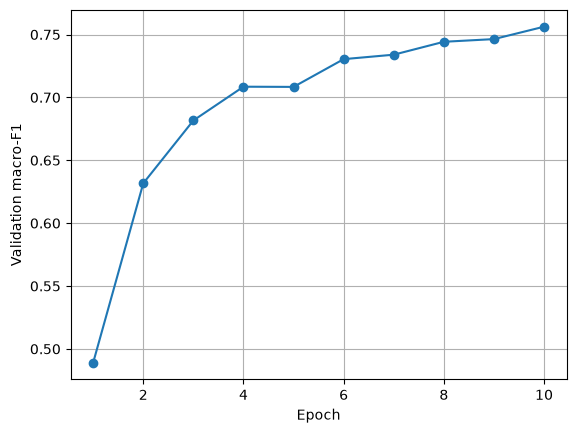

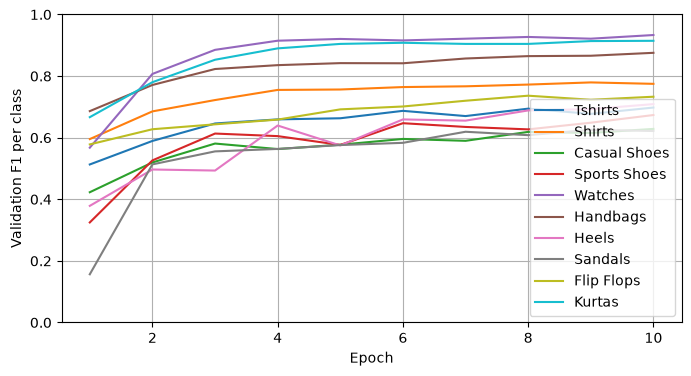

In [18]:
# 수정 금지

epoch_numbers = [row['epoch'] for row in history]  # epoch 번호 목록
plt.plot(epoch_numbers, [row['val_f1'] for row in history], marker='o')  # epoch별 macro-F1 꺾은선
plt.xlabel('Epoch')  # x축 이름
plt.ylabel('Validation macro-F1')  # y축 이름
plt.grid()  # 격자 표시
plt.show()  # 그림 표시

plt.figure(figsize=(8, 4))  # 새 그림
for label, name in enumerate(class_names):  # 클래스마다
    scores = [row[label] for row in class_f1_history]  # 그 클래스의 epoch별 F1
    plt.plot(epoch_numbers, scores, label=name)  # 꺾은선 추가
plt.xlabel('Epoch')  # x축 이름
plt.ylabel('Validation F1 per class')  # y축 이름
plt.ylim(0, 1)  # y축 범위 0~1
plt.legend()  # 범례 표시
plt.grid()  # 격자 표시
plt.show()  # 그림 표시


In [19]:
# 수정 금지

model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))  # 저장된 best 가중치를 다시 불러옴 (weights_only=True: 안전 로딩)
val_loss, val_f1, val_class_f1 = evaluate(model, val_loader, loss_fn)  # 검증
print(f'[Final] Validation macro-F1: {val_f1:.4f}')  # 최종 macro-F1 출력 (채점 기준 값)
print('Class           Validation F1')  # 표 머리글
for name, score in zip(class_names, val_class_f1):  # 클래스 이름과 F1을 함께 돌며
    print(f'{name:14s} {score:13.4f}')  # 이름 14칸, 점수 소수 4자리로 정렬 출력


[Final] Validation macro-F1: 0.7562
Class           Validation F1
Tshirts               0.6979
Shirts                0.7749
Casual Shoes          0.6286
Sports Shoes          0.6736
Watches               0.9333
Handbags              0.8756
Heels                 0.7090
Sandals               0.6218
Flip Flops            0.7330
Kurtas                0.9146


## 제출

아래 파일들을 제출하세요.
- 완성한 노트북 `.ipynb`
- Best 체크포인트 `outputs/F1_1_<수험번호>.pt`

파일명에는 첫 셀의 수험번호가 자동으로 들어갑니다. 따로 이름을 바꿀 필요가 없습니다.

- 실제로 실행하는데 사용된 체크포인트 결과만 제출하세요.
- 실제로 실행한 validation 결과를 노트북에 남기세요.